# Foam flow walkthrough
This notebook builds a pore-throat structure input, runs the LBM solver, loads simulation outputs, and then visualizes bubble evolution.

In [2]:
from pathlib import Path
import os
import re
import sys

import numpy as np
import glob
import pyvista as pv
import matplotlib.pyplot as plt
def initialize_plotter():
    
    # Initialize a PyVista Plotter Object
    plotter_obj = pv.Plotter(off_screen=True)
    
    # Set the background color to white
    plotter_obj.set_background(color='w')
    pv.global_theme.font.color = 'black'
    
    return plotter_obj

cwd = Path.cwd().resolve()
if (cwd / "examples" / "foam_flow").exists():
    repo_root = cwd
    example_dir = cwd / "examples" / "foam_flow"
elif cwd.name == "foam_flow":
    example_dir = cwd
    repo_root = cwd.parents[1]
else:
    raise FileNotFoundError(
        "Run this notebook from the repo root or from examples/foam_flow."
    )

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

os.chdir(example_dir)
from latteasy.preprocessing.create_palabos_geom_script import create_palabos_geom_script
example_dir

PosixPath('/Users/cedar/data/LattEasy-foam/examples/foam_flow')

## Load geometry raw binary file

Visualize binary geometry saved at ./input

/Users/cedar/opt/anaconda3/lib/python3.10/site-packages/pyvista/jupyter/notebook.py:37: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


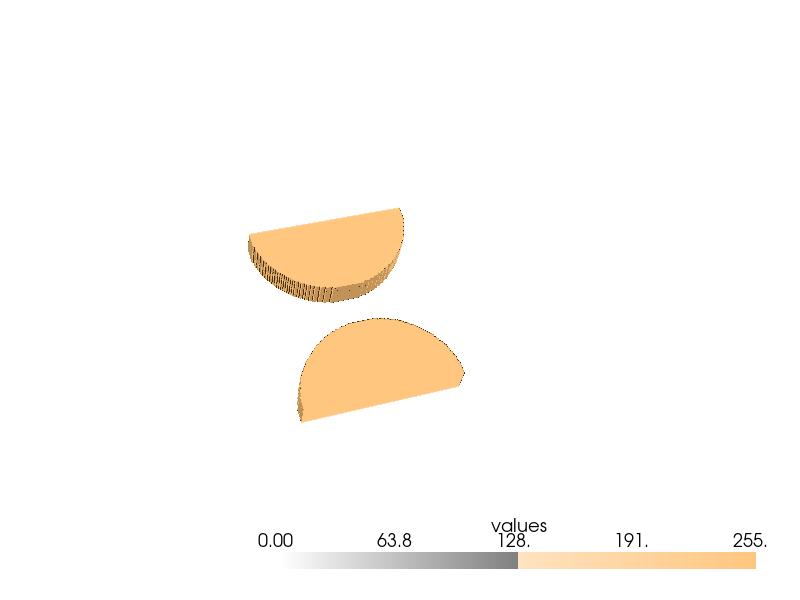

In [3]:
width  = 400
height = 120
slices = 18
filename = "h18_1constriction_channel.raw"
alldata = np.fromfile(cwd / "input" / filename, dtype=np.ubyte, sep="")
image = alldata.reshape([width,height,slices])
image = image.transpose([2,1,0])
pv_img = pv.wrap(image)

cmap = plt.cm.colors.ListedColormap([
    (0, 0, 0, 0),   # 0 → fully transparent
    (1, 0.78, 0.5, 0.13)
])
camera_pos = [(564.6943256732076, 368.3719377040386, 4.84773933199319),
 (8.5, 59.5, 199.5),
 (0.5265770524664042, -0.828703288769812, 0.18965090824430983)]
p = initialize_plotter()
# Generate a contoured surface for rough fracture. 
c = image.reshape(1,-1) 
p.add_volume(image*255, cmap=cmap)
contour = pv_img.contour(isosurfaces=[0.5])
p.add_mesh(contour, color=(0.78, 0.5, 0.13), opacity=1.)

p.show(cpos=camera_pos, auto_close=True, window_size=[800, 600])
p.close()

## Convert geometry into simulation input

Overwrite template input.yml to convert binary geometry into ASCII file.

In [4]:
import yaml

# Path to latteasy/preprocessing/input.yml
input_file = (
    cwd/".."/".."
    / "latteasy"
    / "preprocessing"
    / "input.yml"
)

# Load the existing configuration
with input_file.open("r") as f:
    config = yaml.safe_load(f)

config["input output"]["simulation directory"] = str(cwd)

config["geometry"]["file name"] = filename
config["geometry"]["geometry size"]["Nx"] = width
config["geometry"]["geometry size"]["Ny"] = height
config["geometry"]["geometry size"]["Nz"] = slices

config["domain"]["geom name"] = filename.split(".")[0]
config["domain"]["domain size"]["nx"] = width
config["domain"]["domain size"]["ny"] = height
config["domain"]["domain size"]["nz"] = slices

# Save changes, overwriting input.yml
with input_file.open("w") as f:
    yaml.safe_dump(
        config,
        f,
        sort_keys=False,
        default_flow_style=False,
    )

print(f"Updated: {input_file}")


Updated: /Users/cedar/data/LattEasy-foam/examples/foam_flow/../../latteasy/preprocessing/input.yml


Simulation Directory: /Users/cedar/data/LattEasy-foam/examples/foam_flow
Input Folder: input/
Output Folder: tmp/
Geometry File: h18_1constriction_channel.raw
Geometry Data Type: int8
Geometry Size: Nx=400, Ny=120, Nz=18
Geometry Name: h18_1constriction_channel
Domain Size: nx=400, ny=120, nz=18
Number of Geometries: 1
Applied Pressure: 0.0005
Maximum Iterations: 500000
Convergence: 0.002
Saving Velocity and Medium vtks: True
Creating efficient geometry for Palabos...
Load (400, 120, 18)
subset (400, 120, 18)
rock shape (400, 120, 18)
erase regions (400, 120, 18)
create geom edist (400, 120, 18)


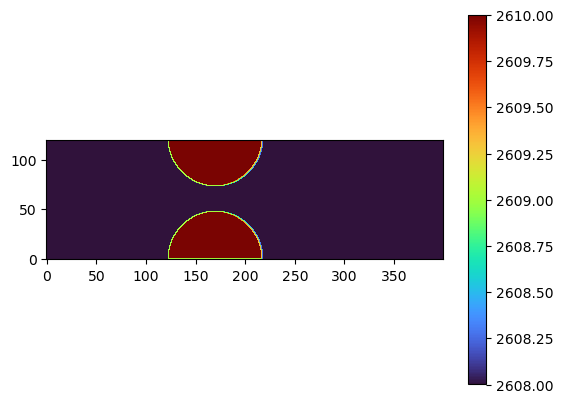

Palabos geometry generation completed.


In [5]:
create_palabos_geom_script()

## Run the simulation

This launches the bundled foam solver with selected MPI process count and MPI launcher.

In [ ]:
import shutil
from latteasy.preprocessing.foam_tools import FoamSimulation

geometry_file = cwd/f"input/{filename}_{width}_{height}_{slices}.dat"
domain_size = (width, height, slices)
num_cores = 4

simulation = FoamSimulation(
    geometry_file, domain_size, cpus=num_cores, mpi_launcher="ibrun",
    params={"geometry": {"fluidPoolHeight_LB": height,}, "Nucleation": {"distribution": "list", "numberOfBubbles": 2, "radius": 10, "shift": 20, "packingOffset": 3},
    "numerics": {"g_LB": -1e-4, "maxIter": 20000,}, "fluid": { "contactAngle": 30.0 }, "output": {"outIter": 500, "save_it": 100000},
    },  
)
for ax in "xyz":
    shutil.copy(f"nucleation_{ax}_points.txt", simulation.out_path)

history_log = simulation.run_sim()

print(f"Cores: {num_cores}")
print(f"Nuclei placed: {len(simulation.nuclei)}")
print(f"Bubble history log: {Path(history_log).resolve()}")
print(f"Simulation folder: {Path(simulation.folder_path).resolve()}")

## Foam propagation

The solver writes intermediate results to `volumeData_*.vti`. This plot extracts volume of fluid values and shows how bubbles evolve in time.


In [ ]:
sim_folder = Path(simulation.folder_path).resolve() #'out'

figures_dir = Path(sim_folder) / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

foam_files_regex = f'{sim_folder}/volumeData_*.vti'
foam_files = glob.glob(foam_files_regex)

# Sort lists for correct order
foam_list = sorted(foam_files)
print(len(foam_list))
x, y, z = np.meshgrid(np.arange(0, height,1),np.arange(0, slices, 1),np.arange(0,width, 1))

41


out/volumeData_00000001.vti


/Users/cedar/opt/anaconda3/lib/python3.10/site-packages/pyvista/jupyter/notebook.py:37: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


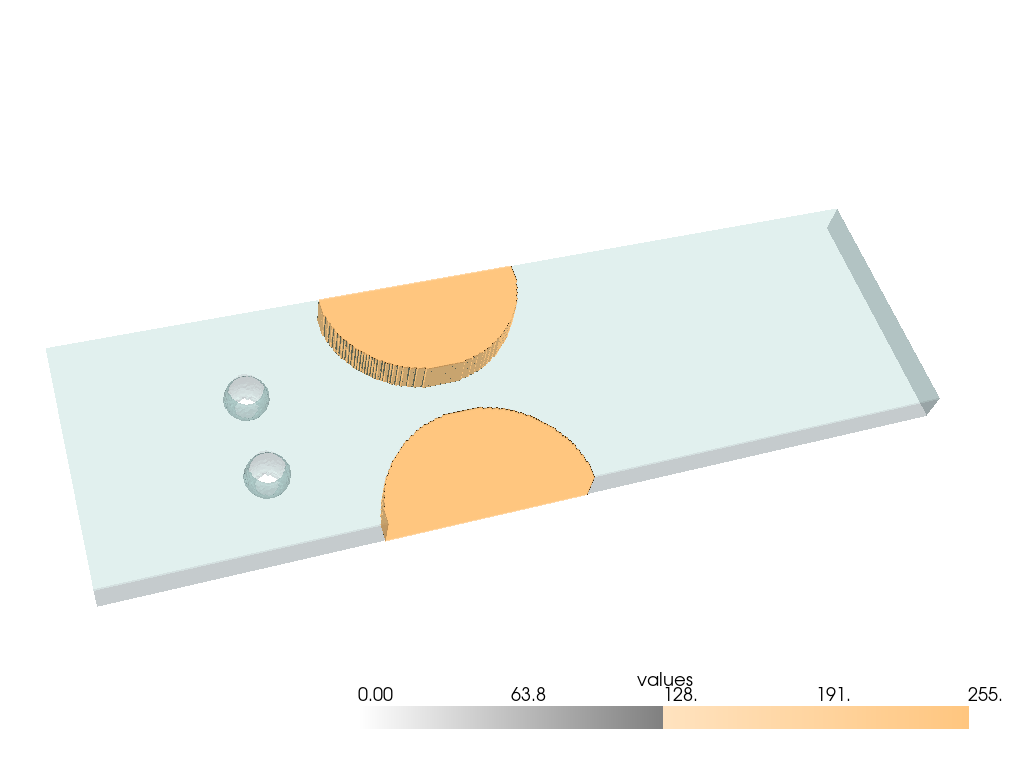

out/volumeData_00010000.vti


/Users/cedar/opt/anaconda3/lib/python3.10/site-packages/pyvista/jupyter/notebook.py:37: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


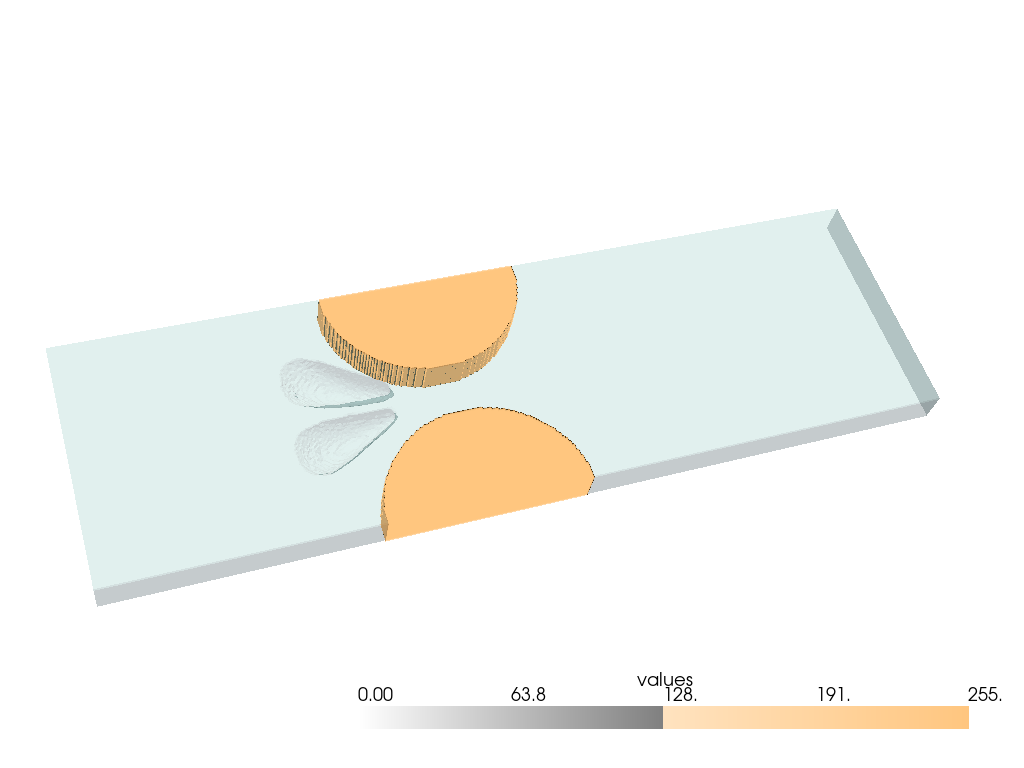

out/volumeData_00019999.vti


/Users/cedar/opt/anaconda3/lib/python3.10/site-packages/pyvista/jupyter/notebook.py:37: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


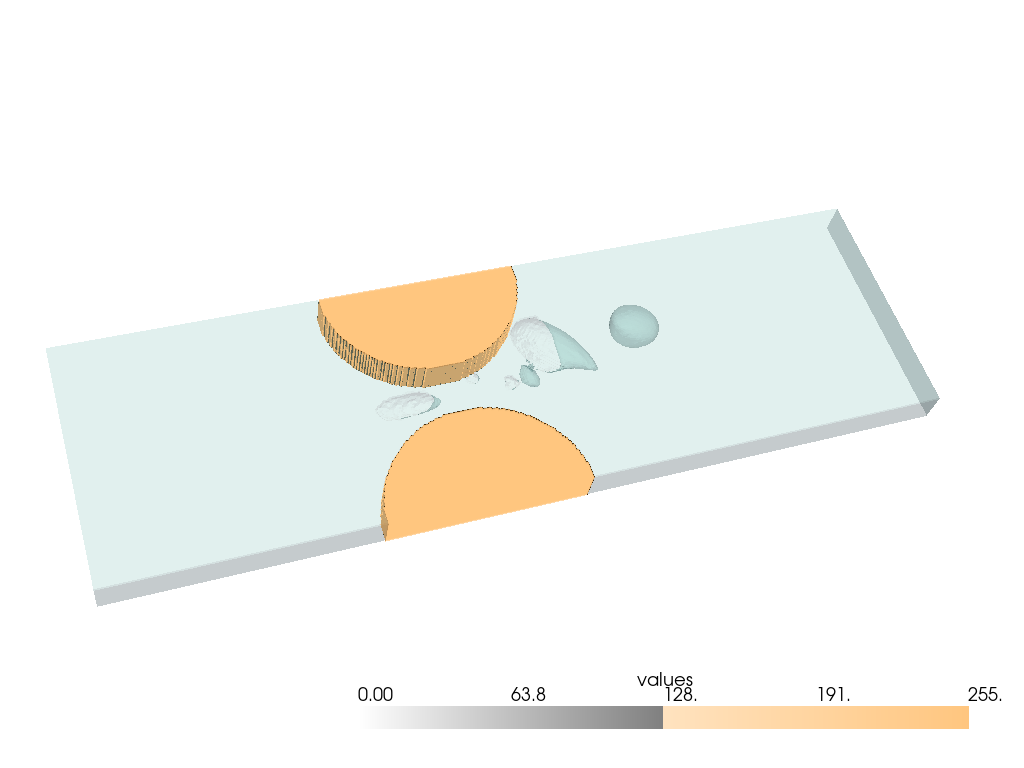

In [ ]:
skip = 20

for i in range(0, len(foam_list), skip):
    p = initialize_plotter()
    # p.clear()
    p.add_volume(image*255, cmap=cmap)
    p.add_mesh(contour, color=(0.78, 0.5, 0.13), opacity=1.)
    
    foam_mesh = pv.read(foam_list[i])
    print(foam_list[i])

    foam_vof = foam_mesh.get_array('volumeFraction').reshape([slices, height, width])

    foam_data = pv.wrap(foam_vof)
    foam_surface = foam_data.contour(isosurfaces=[0.5])
    p.add_mesh(foam_surface,  color='#A8E4EA', opacity = 0.3) 
    p.show(return_cpos=True, auto_close=False, cpos= camera_pos)
    
    p.screenshot(filename=f'{figures_dir}/visualization_{i}.png',return_img=True)
    p.close()